<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/particle_physics/particle_ch02_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Particle Physics* — `particle_ch02_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Particle Physics Ch 2 Figures — Colab Notebook
**Particle Physics · Chapter 2: A First Look at Quantum Fields**

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §2.1   | Dirac equation: spinor structure, antimatter, pair production |
| fig02  | §2.3   | QED Feynman diagrams: vertex, $e^+e^-\to\mu^+\mu^-$, $g-2$ loop |
| fig03  | §2.3   | $\sigma(e^+e^-\to\mu^+\mu^-)$ vs $\sqrt{s}$ — $1/s$ scaling |
| fig04  | §2.4   | Running of $\alpha_{\rm em}$ and QED vacuum polarisation |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Arc, Circle
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
TEAL='#2ec4b6'; BLUE='#7ec8e3'; YELL='#f9c74f'
GREEN='#90ee90'; RED='#e07070'; PURP='#c792ea'; ORAN='#ffa657'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':TEAL,'legend.framealpha':0.3,
    'legend.edgecolor':EDGE,'lines.linewidth':2.2,
    'axes.linewidth':1.2,'figure.dpi':110,
})

OUTDIR = 'figures/ch02'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete.')

Setup complete.


---
## fig01 · Dirac Equation & Antimatter (§2.1)

/tmp/ipykernel_844/1367574829.py:68: RuntimeWarning: divide by zero encountered in divide
  (1 - thresh/x) * (1 + thresh/(2*x)) * np.log(x/thresh + 1), 0)
/tmp/ipykernel_844/1367574829.py:68: RuntimeWarning: invalid value encountered in multiply
  (1 - thresh/x) * (1 + thresh/(2*x)) * np.log(x/thresh + 1), 0)


  saved -> figures/ch02/fig01_dirac.png


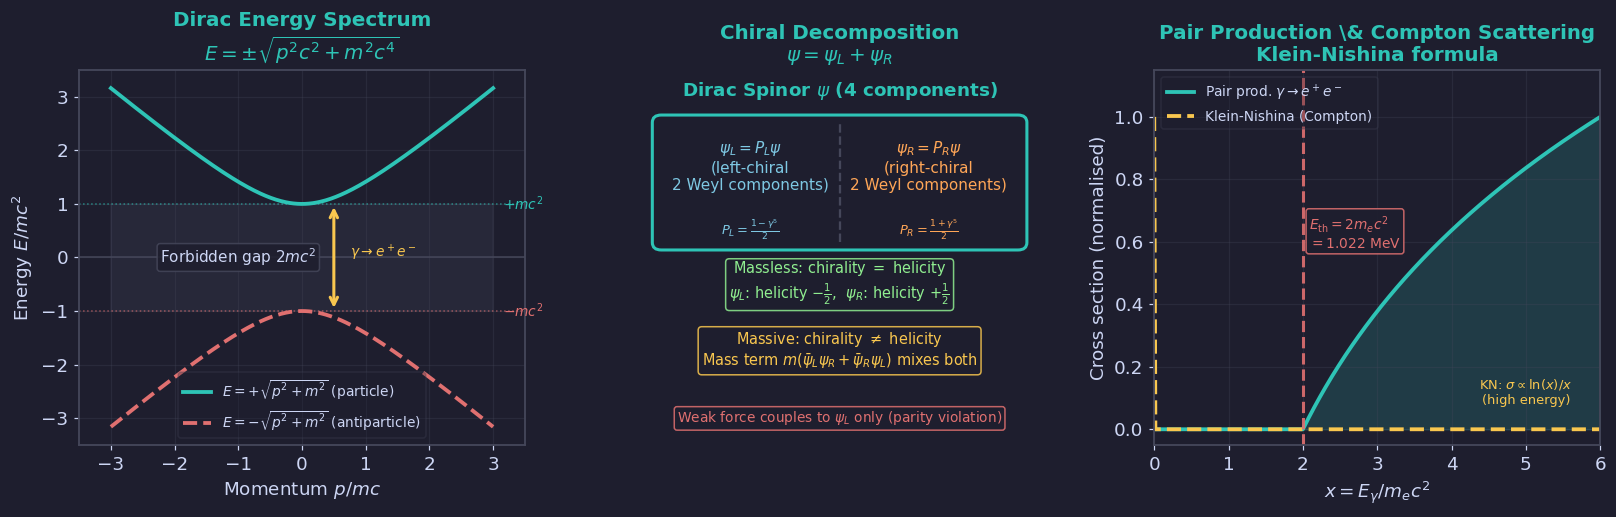

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Dirac energy spectrum ───────────────────────────────────────────
ax = axes[0]; ax.set_facecolor(BG)
p_arr = np.linspace(-3, 3, 300); m = 1.0
E_pos = np.sqrt(p_arr**2 + m**2); E_neg = -E_pos

ax.plot(p_arr, E_pos, color=TEAL, lw=2.5, label=r'$E=+\sqrt{p^2+m^2}$ (particle)')
ax.plot(p_arr, E_neg, color=RED,  lw=2.5, ls='--', label=r'$E=-\sqrt{p^2+m^2}$ (antiparticle)')
ax.fill_between(p_arr, -m, m, color=EDGE, alpha=0.25)
ax.text(-1.0, 0, r'Forbidden gap $2mc^2$', ha='center', va='center', fontsize=10, color=FG,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=EDGE, alpha=0.85))
ax.annotate('', xy=(0.5, E_pos[150]), xytext=(0.5, E_neg[150]),
            arrowprops=dict(arrowstyle='<->', color=YELL, lw=2))
ax.text(0.75, 0.0, r'$\gamma\to e^+e^-$', fontsize=9, color=YELL)
ax.axhline( m, color=TEAL, lw=1, ls=':', alpha=0.6)
ax.axhline(-m, color=RED,  lw=1, ls=':', alpha=0.6)
ax.text(3.15,  m, r'$+mc^2$', fontsize=9, color=TEAL, va='center')
ax.text(3.15, -m, r'$-mc^2$', fontsize=9, color=RED,  va='center')
ax.set_xlabel(r'Momentum $p/mc$'); ax.set_ylabel(r'Energy $E/mc^2$')
ax.set_title('Dirac Energy Spectrum\n'+r'$E=\pm\sqrt{p^2c^2+m^2c^4}$')
ax.legend(fontsize=9, labelcolor=FG, loc="lower center")
ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
ax.axhline(0, color=EDGE, lw=1); ax.grid(True, alpha=0.3)

# ── Middle: Chiral decomposition (corrected: helicity=chirality only massless) ──
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.text(0.5, 0.93, r'Dirac Spinor $\psi$ (4 components)', ha='center',
         fontsize=12, color=TEAL, fontweight='bold', transform=ax2.transAxes)
box = FancyBboxPatch((0.10, 0.54), 0.80, 0.32,
                     boxstyle='round,pad=0.02', facecolor=BG, edgecolor=TEAL,
                     linewidth=2, transform=ax2.transAxes)
ax2.add_patch(box)
ax2.plot([0.50, 0.50], [0.54, 0.86], color=EDGE, lw=1.5, ls='--',
         transform=ax2.transAxes)
ax2.text(0.30, 0.68, r'$\psi_L = P_L\psi$'+'\n(left-chiral\n2 Weyl components)',
         ha='center', fontsize=10, color=BLUE, transform=ax2.transAxes)
ax2.text(0.70, 0.68, r'$\psi_R = P_R\psi$'+'\n(right-chiral\n2 Weyl components)',
         ha='center', fontsize=10, color=ORAN, transform=ax2.transAxes)
ax2.text(0.30, 0.56, r'$P_L=\frac{1-\gamma^5}{2}$', ha='center', fontsize=8.5,
         color=BLUE, transform=ax2.transAxes)
ax2.text(0.70, 0.56, r'$P_R=\frac{1+\gamma^5}{2}$', ha='center', fontsize=8.5,
         color=ORAN, transform=ax2.transAxes)
ax2.text(0.5, 0.39,
         r'Massless: chirality $=$ helicity'+'\n'+
         r'$\psi_L$: helicity $-\frac{1}{2}$,  $\psi_R$: helicity $+\frac{1}{2}$',
         ha='center', fontsize=9.5, color=GREEN, transform=ax2.transAxes,
         bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=GREEN, alpha=0.85))
ax2.text(0.5, 0.21,
         r'Massive: chirality $\neq$ helicity'+'\n'+
         r'Mass term $m(\bar\psi_L\psi_R+\bar\psi_R\psi_L)$ mixes both',
         ha='center', fontsize=9.5, color=YELL, transform=ax2.transAxes,
         bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=YELL, alpha=0.85))
ax2.text(0.5, 0.06,
         r'Weak force couples to $\psi_L$ only (parity violation)',
         ha='center', fontsize=9, color=RED, transform=ax2.transAxes,
         bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=RED, alpha=0.85))
ax2.set_title('Chiral Decomposition\n'+r'$\psi = \psi_L + \psi_R$', color=TEAL)

# ── Right: Pair production (Bethe-Heitler) + Klein-Nishina Compton ────────
ax3 = axes[2]; ax3.set_facecolor(BG)
x = np.linspace(0, 6, 400)   # x = E_gamma / (m_e c^2)

# Pair production: Bethe-Heitler near-threshold schematic
thresh = 2.0
sigma_pair = np.where(x > thresh,
    (1 - thresh/x) * (1 + thresh/(2*x)) * np.log(x/thresh + 1), 0)
sigma_pair = sigma_pair / sigma_pair.max()

# Klein-Nishina Compton (exact formula, normalised to Thomson at x→0)
def klein_nishina(x):
    x = np.maximum(x, 1e-6)
    return (3/4)*((1+x)/x**3*(2*x*(1+x)/(1+2*x)-np.log(1+2*x))
                  + np.log(1+2*x)/(2*x) - (1+3*x)/(1+2*x)**2)
sigma_kn = np.clip(klein_nishina(x)/klein_nishina(1e-6), 0, None)

ax3.fill_between(x, 0, sigma_pair, color=TEAL, alpha=0.18)
ax3.plot(x, sigma_pair, color=TEAL, lw=2.5, label=r'Pair prod. $\gamma\to e^+e^-$')
ax3.plot(x, sigma_kn,   color=YELL, lw=2.5, ls='--', label='Klein-Nishina (Compton)')
ax3.axvline(thresh, color=RED, lw=2, ls='--', alpha=0.9)
ax3.text(thresh+0.08, 0.58, r'$E_{\rm th}=2m_ec^2$'+'\n$=1.022$ MeV',
         fontsize=9, color=RED,
         bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=RED, alpha=0.85))
ax3.text(5.0, 0.08, r'KN: $\sigma\propto\ln(x)/x$'+'\n(high energy)',
         fontsize=8.5, color=YELL, ha='center')
ax3.set_xlabel(r'$x = E_\gamma / m_e c^2$')
ax3.set_ylabel('Cross section (normalised)')
ax3.set_title(r'Pair Production \& Compton Scattering'+'\nKlein-Nishina formula')
ax3.legend(fontsize=9, labelcolor=FG)
ax3.set_xlim(0, 6); ax3.set_ylim(-0.05, 1.15)
ax3.grid(True, alpha=0.3)

plt.tight_layout(pad=1.5)
save('fig01_dirac.png', fig)


---
## fig02 · QED Feynman Diagrams (§2.3)

  saved -> figures/ch02/fig02_feynman.png


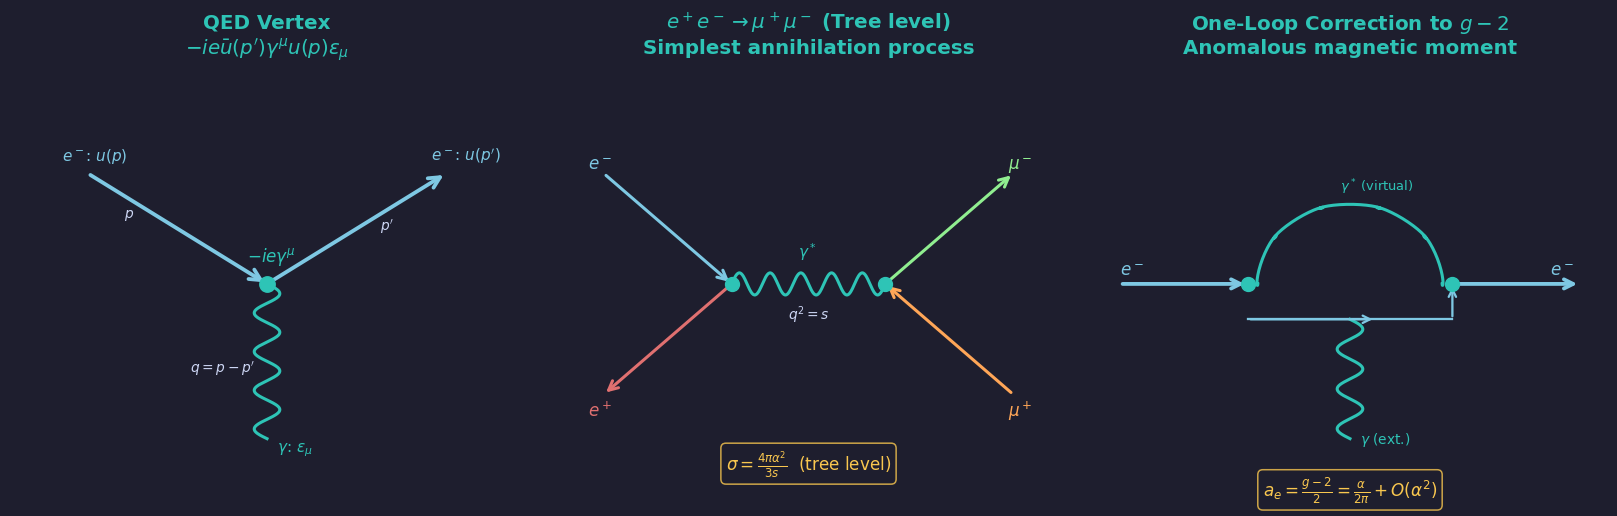

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: QED vertex diagram ──────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG); ax.axis('off')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)

def wavy_line(ax, x1, y1, x2, y2, col=TEAL, n_waves=5, amp=0.025, lw=2):
    """Draw a wavy line (photon)."""
    t = np.linspace(0, 1, 300)
    dx, dy = x2-x1, y2-y1
    length = np.sqrt(dx**2 + dy**2)
    # Perpendicular direction
    px, py = -dy/length, dx/length
    wave = amp * np.sin(n_waves * 2*np.pi * t)
    x = x1 + t*dx + wave*px
    y = y1 + t*dy + wave*py
    ax.plot(x, y, color=col, lw=lw)

# Vertex at centre
vx, vy = 0.5, 0.5
ax.plot(vx, vy, 'o', color=TEAL, ms=10, zorder=5)
ax.text(vx-0.04, vy+0.05, r'$-ie\gamma^\mu$', fontsize=11, color=TEAL)

# Incoming electron
ax.annotate('', xy=(vx, vy), xytext=(0.15, 0.75),
            arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5, mutation_scale=18))
ax.text(0.10, 0.78, r'$e^-$: $u(p)$', fontsize=10, color=BLUE)

# Outgoing electron
ax.annotate('', xy=(0.85, 0.75), xytext=(vx, vy),
            arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5, mutation_scale=18))
ax.text(0.82, 0.78, r"$e^-$: $u(p')$", fontsize=10, color=BLUE)

# Photon (wavy line downward)
wavy_line(ax, vx, vy, 0.5, 0.15, col=TEAL, n_waves=4)
ax.text(0.52, 0.12, r'$\gamma$: $\epsilon_\mu$', fontsize=10, color=TEAL)

# Momentum labels
ax.text(0.22, 0.65, r'$p$', fontsize=9, color=FG)
ax.text(0.72, 0.62, r"$p'$", fontsize=9, color=FG)
ax.text(0.35, 0.30, r"$q=p-p'$", fontsize=9, color=FG)

ax.set_title('QED Vertex\n'+r"$-ie\bar u(p')\gamma^\mu u(p)\epsilon_\mu$")

# ── Middle: e+e- → mu+mu- diagram ────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_xlim(0, 1); ax2.set_ylim(0, 1)

# Photon propagator (horizontal wavy)
wavy_line(ax2, 0.35, 0.5, 0.65, 0.5, col=TEAL, n_waves=5)
ax2.text(0.48, 0.56, r'$\gamma^*$', fontsize=10, color=TEAL)
ax2.text(0.46, 0.42, r'$q^2=s$', fontsize=9, color=FG)

# e- incoming (top-left)
ax2.annotate('', xy=(0.35, 0.5), xytext=(0.10, 0.75),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2, mutation_scale=15))
ax2.text(0.07, 0.76, r'$e^-$', fontsize=11, color=BLUE)

# e+ incoming (bottom-left)
ax2.annotate('', xy=(0.10, 0.25), xytext=(0.35, 0.5),
             arrowprops=dict(arrowstyle='->', color=RED, lw=2, mutation_scale=15))
ax2.text(0.07, 0.20, r'$e^+$', fontsize=11, color=RED)

# mu- outgoing (top-right)
ax2.annotate('', xy=(0.90, 0.75), xytext=(0.65, 0.5),
             arrowprops=dict(arrowstyle='->', color=GREEN, lw=2, mutation_scale=15))
ax2.text(0.89, 0.76, r'$\mu^-$', fontsize=11, color=GREEN)

# mu+ outgoing (bottom-right)
ax2.annotate('', xy=(0.65, 0.5), xytext=(0.90, 0.25),
             arrowprops=dict(arrowstyle='->', color=ORAN, lw=2, mutation_scale=15))
ax2.text(0.89, 0.20, r'$\mu^+$', fontsize=11, color=ORAN)

# Vertices
for vpos in [(0.35, 0.5), (0.65, 0.5)]:
    ax2.plot(*vpos, 'o', color=TEAL, ms=9, zorder=5)

ax2.text(0.5, 0.08,
         r'$\sigma=\frac{4\pi\alpha^2}{3s}$' + "  (tree level)",
         ha='center', fontsize=11, color=YELL,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=YELL, alpha=0.8))

ax2.set_title(r'$e^+e^-\to\mu^+\mu^-$ (Tree level)' + "\nSimplest annihilation process")

# ── Right: g-2 one-loop diagram ───────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG); ax3.axis('off')
ax3.set_xlim(0, 1); ax3.set_ylim(0, 1)

# Electron line with photon loop
# Incoming electron line
ax3.annotate('', xy=(0.30, 0.50), xytext=(0.05, 0.50),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5, mutation_scale=15))
# Loop starts at vertex 1
ax3.plot(0.30, 0.50, 'o', color=TEAL, ms=9, zorder=5)
# Virtual photon (semi-circle above)
theta_arc = np.linspace(0, np.pi, 100)
x_arc = 0.50 + 0.18*np.cos(np.pi - theta_arc)  # arc from 0.30 to 0.70
y_arc = 0.50 + 0.18*np.sin(theta_arc)
# Make it wavy
n_w = 5
perp_x = -np.sin(np.pi - theta_arc)
perp_y = np.cos(np.pi - theta_arc)
wave_arc = 0.025 * np.sin(n_w * 2*np.pi * np.linspace(0, 1, 100))
ax3.plot(x_arc + wave_arc*perp_x, y_arc + wave_arc*perp_y, color=TEAL, lw=2)

# Electron propagator in loop (bottom)
ax3.annotate('', xy=(0.55, 0.42), xytext=(0.30, 0.42),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=1.5, mutation_scale=12))
ax3.plot([0.30, 0.70], [0.42, 0.42], color=BLUE, lw=1.5)
ax3.annotate('', xy=(0.70, 0.50), xytext=(0.70, 0.42),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=1.5, mutation_scale=12))

# Vertex 2
ax3.plot(0.70, 0.50, 'o', color=TEAL, ms=9, zorder=5)
# Outgoing electron line
ax3.annotate('', xy=(0.95, 0.50), xytext=(0.70, 0.50),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5, mutation_scale=15))

# External photon (bottom)
wavy_line(ax3, 0.50, 0.15, 0.50, 0.42, col=TEAL, n_waves=3)
ax3.text(0.52, 0.14, r'$\gamma$ (ext.)', fontsize=9, color=TEAL)

# Labels
ax3.text(0.05, 0.52, r'$e^-$', fontsize=11, color=BLUE)
ax3.text(0.89, 0.52, r'$e^-$', fontsize=11, color=BLUE)
ax3.text(0.48, 0.71, r'$\gamma^*$ (virtual)', fontsize=8.5, color=TEAL)

ax3.text(0.5, 0.02,
         r'$a_e = \frac{g-2}{2} = \frac{\alpha}{2\pi} + O(\alpha^2)$',
         ha='center', fontsize=11, color=YELL,
         bbox=dict(boxstyle='round,pad=0.3', facecolor=BG, edgecolor=YELL, alpha=0.8))

ax3.set_title(r'One-Loop Correction to $g-2$'+"\nAnomalous magnetic moment")

plt.tight_layout(pad=1.5)
save('fig02_feynman.png', fig)

---
## fig03 · Cross Section $e^+e^-\to\mu^+\mu^-$ (§2.3)
## fig04 · Running of $\alpha_{\rm em}$ (§2.4)

  saved -> figures/ch02/fig03_cross_section.png


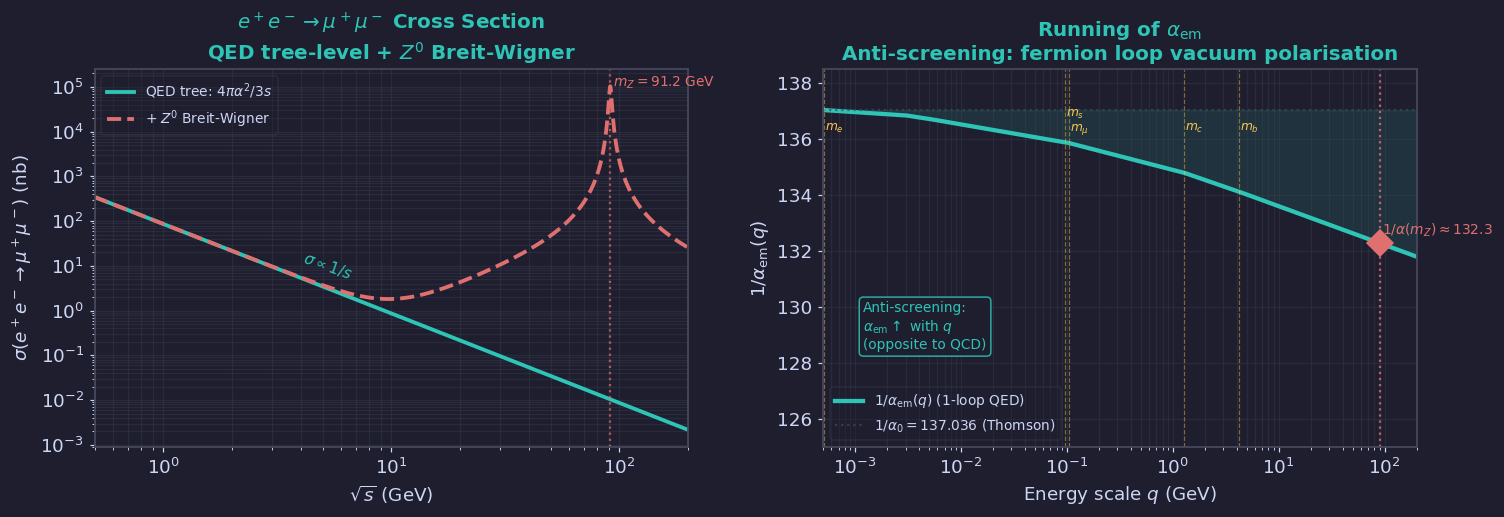

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# ── Left: sigma(e+e-→mu+mu-) with proper Breit-Wigner ────────────────────
ax = axes[0]; ax.set_facecolor(BG)
sqrt_s = np.linspace(0.5, 200, 3000)
alpha0 = 1/137.036
conv   = 3.894e5   # GeV^{-2} → nb  (1 GeV^{-2} = 0.3894 mb)

# QED tree-level sigma
sigma_qed = 4*np.pi*alpha0**2 / (3 * sqrt_s**2) * conv

# Z resonance: proper Breit-Wigner ADDED to QED background
# sigma_Z(s) = 12pi * Gamma_ee * Gamma_mumu / m_Z^2
#              * (s * m_Z^2 * Gamma_Z^2) / ((s-m_Z^2)^2 + s^2*Gamma_Z^2/m_Z^2)
m_Z = 91.2; Gamma_Z = 2.4952; Gamma_ee = 0.08399  # GeV (PDG)
s = sqrt_s**2
sigma_Z = (12*np.pi/m_Z**2 * Gamma_ee**2
           * (s * m_Z**2 * Gamma_Z**2)
           / ((s - m_Z**2)**2 + s**2*Gamma_Z**2/m_Z**2)
           * conv)
sigma_total = sigma_qed + sigma_Z

ax.loglog(sqrt_s, sigma_qed,   color=TEAL, lw=2.5,
          label=r'QED tree: $4\pi\alpha^2/3s$')
ax.loglog(sqrt_s, sigma_total, color=RED,  lw=2.5, ls='--',
          label=r'$+\;Z^0$ Breit-Wigner')
ax.axvline(m_Z, color=RED, lw=1.5, ls=':', alpha=0.7)
ax.text(m_Z*1.03, 1e5, r'$m_Z=91.2$ GeV', fontsize=9, color=RED)
ax.text(4, 5, r'$\sigma\propto 1/s$', fontsize=10, color=TEAL, rotation=-20)
ax.set_xlabel(r'$\sqrt{s}$ (GeV)')
ax.set_ylabel(r'$\sigma(e^+e^-\to\mu^+\mu^-)$ (nb)')
ax.set_title(r'$e^+e^-\to\mu^+\mu^-$ Cross Section'+'\n'+
             r'QED tree-level + $Z^0$ Breit-Wigner')
ax.legend(fontsize=9, labelcolor=FG)
ax.set_xlim(0.5, 200); ax.grid(True, which='both', alpha=0.3)

# ── Right: Running alpha_em (correct 1-loop formula, consistent GeV units) ──
ax2 = axes[1]; ax2.set_facecolor(BG)
alpha0_inv = 137.036
# Fermion masses ALL in GeV; 1-loop: delta(1/alpha) = -Nc Qf^2/(3pi) ln(q/mf) [q > mf]
fermions = [
    (0.511e-3, 1,   1, r'$m_e$', 136.3),
    (0.1057,   1,   1, r'$m_\mu$', 136.3),
    (0.003,    2/3, 3, None, 136.3),        # u (label suppressed: too close to d)
    (0.005,    1/3, 3, None, 136.3),        # d
    (0.096,    1/3, 3, r'$m_s$', 136.8),
    (1.275,    2/3, 3, r'$m_c$', 136.3),
    (4.180,    1/3, 3, r'$m_b$', 136.3),
]
q_arr = np.logspace(-3.5, np.log10(200), 600)
delta_inv = np.zeros_like(q_arr)
for (m_f, Q_f, N_c, _, _) in fermions:
    delta_inv += np.where(q_arr > m_f, N_c*Q_f**2/(3*np.pi)*np.log(q_arr/m_f), 0)
alpha_inv = alpha0_inv - delta_inv   # decreases at high q → alpha increases

ax2.semilogx(q_arr, alpha_inv, color=TEAL, lw=2.8,
             label=r'$1/\alpha_{\rm em}(q)$ (1-loop QED)')
ax2.fill_between(q_arr, alpha_inv, alpha0_inv, color=TEAL, alpha=0.12)
ax2.axhline(alpha0_inv, color=EDGE, lw=1.5, ls=':', alpha=0.7,
            label=fr'$1/\alpha_0={alpha0_inv:.3f}$ (Thomson)')

for (m_f, _, _, lbl, y_) in fermions:
    if lbl is None: continue
    ax2.axvline(m_f, color=YELL, lw=0.8, ls='--', alpha=0.45)
    ax2.text(m_f*1.02, y_, lbl, fontsize=8, color=YELL)

alpha_Z = np.interp(91.2, q_arr, alpha_inv)
ax2.plot(91.2, alpha_Z, 'D', color=RED, ms=12, zorder=5)
ax2.text(95, alpha_Z+0.3, fr'$1/\alpha(m_Z)\approx{alpha_Z:.1f}$', fontsize=9, color=RED)
ax2.axvline(91.2, color=RED, lw=1.5, ls=':', alpha=0.8)
ax2.text(0.0012, 128.5,
         'Anti-screening:\n'+r'$\alpha_{\rm em}\uparrow$ with $q$'+'\n(opposite to QCD)',
         fontsize=9, color=TEAL,
         bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=TEAL, alpha=0.85))
ax2.set_xlabel(r'Energy scale $q$ (GeV)')
ax2.set_ylabel(r'$1/\alpha_{\rm em}(q)$')
ax2.set_title(r'Running of $\alpha_{\rm em}$'+'\n'+
              r'Anti-screening: fermion loop vacuum polarisation')
ax2.legend(fontsize=9, labelcolor=FG)
ax2.set_xlim(0.0005, 200); ax2.set_ylim(125, 138.5)
ax2.grid(True, which='both', alpha=0.3)

plt.tight_layout(pad=1.5)
save('fig03_cross_section.png', fig)


In [5]:
import shutil
from google.colab import files

shutil.make_archive('particle_ch02_figures', 'zip', '.', 'figures')
files.download('particle_ch02_figures.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>